# US Traffic Fatality Prediction — Data Modeling
**DATA 495: Data Science Capstone**
**Carl Stolpe | UMGC | May 2026** (data-coding fixes November 2026)

This notebook trains and evaluates two supervised classification models — Logistic Regression and Random Forest — on the NHTSA FARS 2015–2016 driver-level dataset.

**What is being predicted:** FARS contains only crashes in which someone died. The model predicts whether **a driver involved in a fatal crash was fatally injured** — not whether a crash will be fatal.

The dataset uses a temporal train/validation split:
- **Training:** 2015 FARS drivers
- **Validation:** 2016 FARS drivers

**Target variable:** `INJ_SEV` recoded as binary — fatal injury (1) vs. other known severity levels (0)

## 1. Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

import os
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42
os.makedirs('../outputs/figures', exist_ok=True)
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Load Prepared Data

Load the cleaned, feature-engineered datasets produced in `02_data_preparation.ipynb`.  
The 2015 dataset is used for training; the 2016 dataset is the held-out validation set.

In [2]:
# Load prepared datasets
train_df = pd.read_csv('../data/fars_2015_prepared.csv')
val_df   = pd.read_csv('../data/fars_2016_prepared.csv')

print(f'Training set (2015):   {train_df.shape[0]:,} records, {train_df.shape[1]} columns')
print(f'Validation set (2016): {val_df.shape[0]:,} records, {val_df.shape[1]} columns')

# Confirm class distribution
print(f"\nTraining fatal rate:   {train_df['INJ_SEV_BINARY'].mean():.1%}")
print(f"Validation fatal rate: {val_df['INJ_SEV_BINARY'].mean():.1%}")

Training set (2015):   48,533 records, 16 columns
Validation set (2016): 51,195 records, 16 columns

Training fatal rate:   46.1%
Validation fatal rate: 46.3%


## 3. Define Features and Target

In [3]:
# Model features (see 02_data_preparation.ipynb). FATALS and ALC_TESTED are
# excluded because they are only known after the outcome.
NUMERIC_FEATURES = [
    'AGE',          # Driver age
    'HOUR',         # Hour of crash
    'MONTH',        # Month of crash
    'DRUNK_DR',     # Number of drinking drivers in crash
]
CATEGORICAL_FEATURES = [
    'SEX',          # Driver sex
    'LGT_COND',     # Light condition
    'WEATHER',      # Atmospheric conditions
    'MAN_COLL',     # Manner of collision
    'FUNC_SYS',     # Road functional class (Interstate ... local)
    'RURAL_URBAN',  # 1 = rural, 0 = urban (from RUR_URB)
    'STATE',        # State FIPS code
    'REST_USE',     # Restraint use code
    'ALC_POSITIVE', # Measured BAC >= 0.08
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = 'INJ_SEV_BINARY'

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_val   = val_df[FEATURES]
y_val   = val_df[TARGET]

print(f'Feature matrix shape — Train: {X_train.shape}, Validation: {X_val.shape}')
print(f'Class balance — Train: {y_train.value_counts().to_dict()}')

Feature matrix shape — Train: (48533, 13), Validation: (51195, 13)
Class balance — Train: {0: 26183, 1: 22350}


## 4. Model 1 — Logistic Regression

Logistic Regression serves as the interpretable baseline model. Category codes (state, weather, restraint use, etc.) are **one-hot encoded** so the model does not treat, for example, state 48 as "more" than state 6; numeric features are standardized. Class weighting is applied to address class imbalance.

In [4]:
lr_preprocess = ColumnTransformer([
    ('num', StandardScaler(), NUMERIC_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_FEATURES),
])

lr_model = make_pipeline(
    lr_preprocess,
    LogisticRegression(
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=RANDOM_STATE
    )
)

lr_model.fit(X_train, y_train)
print('Logistic Regression training complete.')

Logistic Regression training complete.


In [5]:
# Predictions
lr_preds      = lr_model.predict(X_val)
lr_probs      = lr_model.predict_proba(X_val)[:, 1]

# Metrics
lr_accuracy   = accuracy_score(y_val, lr_preds)
lr_precision  = precision_score(y_val, lr_preds)
lr_recall     = recall_score(y_val, lr_preds)
lr_f1         = f1_score(y_val, lr_preds)
lr_auc        = roc_auc_score(y_val, lr_probs)

print('Logistic Regression — 2016 Validation Performance')
print('-' * 48)
print(f'Accuracy:  {lr_accuracy:.4f}')
print(f'Precision: {lr_precision:.4f}')
print(f'Recall:    {lr_recall:.4f}')
print(f'F1 Score:  {lr_f1:.4f}')
print(f'AUC-ROC:   {lr_auc:.4f}')

Logistic Regression — 2016 Validation Performance
------------------------------------------------
Accuracy:  0.7672
Precision: 0.7806
Recall:    0.6918
F1 Score:  0.7335
AUC-ROC:   0.8292


## 5. Model 2 — Random Forest

Random Forest is the primary model, selected for its ability to capture non-linear feature interactions. 200 trees with max depth of 12 and class weighting applied. Trees split on code values directly, so the category codes are left as-is (unknowns are their own `-1` code).

In [6]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print('Random Forest training complete.')

Random Forest training complete.


In [7]:
# Predictions
rf_preds      = rf_model.predict(X_val)
rf_probs      = rf_model.predict_proba(X_val)[:, 1]

# Metrics
rf_accuracy   = accuracy_score(y_val, rf_preds)
rf_precision  = precision_score(y_val, rf_preds)
rf_recall     = recall_score(y_val, rf_preds)
rf_f1         = f1_score(y_val, rf_preds)
rf_auc        = roc_auc_score(y_val, rf_probs)

print('Random Forest — 2016 Validation Performance')
print('-' * 48)
print(f'Accuracy:  {rf_accuracy:.4f}')
print(f'Precision: {rf_precision:.4f}')
print(f'Recall:    {rf_recall:.4f}')
print(f'F1 Score:  {rf_f1:.4f}')
print(f'AUC-ROC:   {rf_auc:.4f}')

Random Forest — 2016 Validation Performance
------------------------------------------------
Accuracy:  0.7720
Precision: 0.7705
Recall:    0.7230
F1 Score:  0.7460
AUC-ROC:   0.8434


## 6. Model Comparison Table

In [8]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC'],
    'Logistic Regression': [lr_accuracy, lr_precision, lr_recall, lr_f1, lr_auc],
    'Random Forest':       [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_auc],
})

comparison['Difference (RF - LR)'] = (
    comparison['Random Forest'] - comparison['Logistic Regression']
)
comparison['Better Model'] = np.where(
    comparison['Random Forest'] >= comparison['Logistic Regression'],
    'Random Forest', 'Logistic Regression')

comparison = comparison.set_index('Metric')
print(comparison.round(4).to_string())

           Logistic Regression  Random Forest  Difference (RF - LR)         Better Model
Metric                                                                                  
Accuracy                0.7672         0.7720                0.0048        Random Forest
Precision               0.7806         0.7705               -0.0101  Logistic Regression
Recall                  0.6918         0.7230                0.0312        Random Forest
F1 Score                0.7335         0.7460                0.0125        Random Forest
AUC-ROC                 0.8292         0.8434                0.0142        Random Forest


## 7. Confusion Matrices

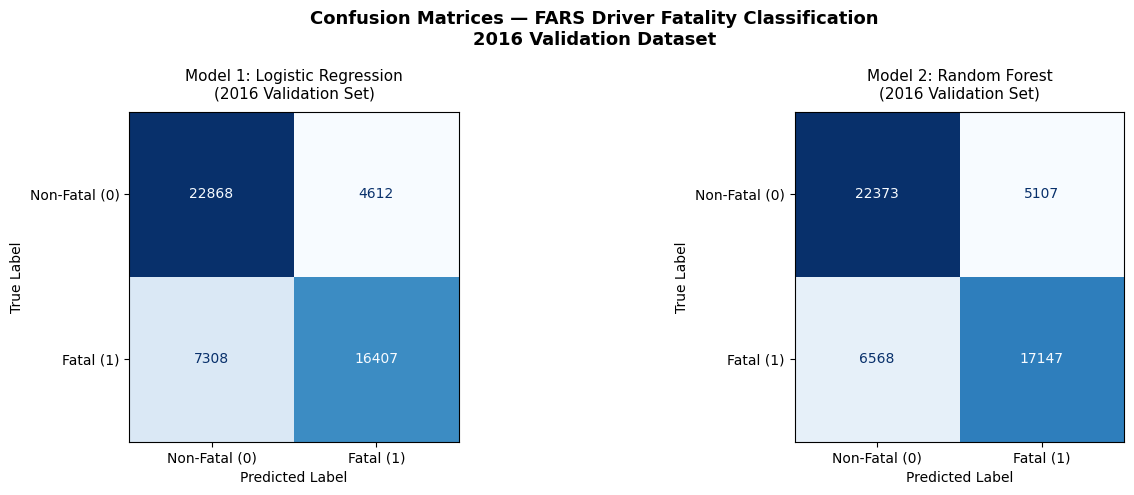

Figure saved.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrices — FARS Driver Fatality Classification\n2016 Validation Dataset',
             fontsize=13, fontweight='bold')

for ax, preds, title in zip(
    axes,
    [lr_preds, rf_preds],
    ['Model 1: Logistic Regression\n(2016 Validation Set)',
     'Model 2: Random Forest\n(2016 Validation Set)']
):
    cm = confusion_matrix(y_val, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=['Non-Fatal (0)', 'Fatal (1)'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title, fontsize=11, pad=10)
    ax.set_xlabel('Predicted Label', fontsize=10)
    ax.set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.savefig('../outputs/figures/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')

## 8. ROC Curves

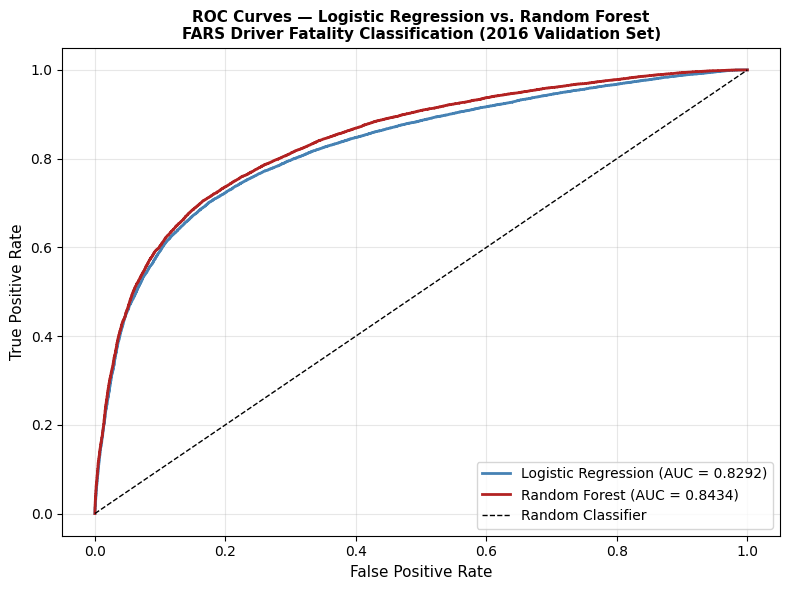

Figure saved.


In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

for probs, auc, label, color in [
    (lr_probs, lr_auc, f'Logistic Regression (AUC = {lr_auc:.4f})', 'steelblue'),
    (rf_probs, rf_auc, f'Random Forest (AUC = {rf_auc:.4f})',        'firebrick')
]:
    fpr, tpr, _ = roc_curve(y_val, probs)
    ax.plot(fpr, tpr, label=label, color=color, linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('ROC Curves — Logistic Regression vs. Random Forest\nFARS Driver Fatality Classification (2016 Validation Set)',
             fontsize=11, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/figures/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')

## 9. Random Forest Feature Importance

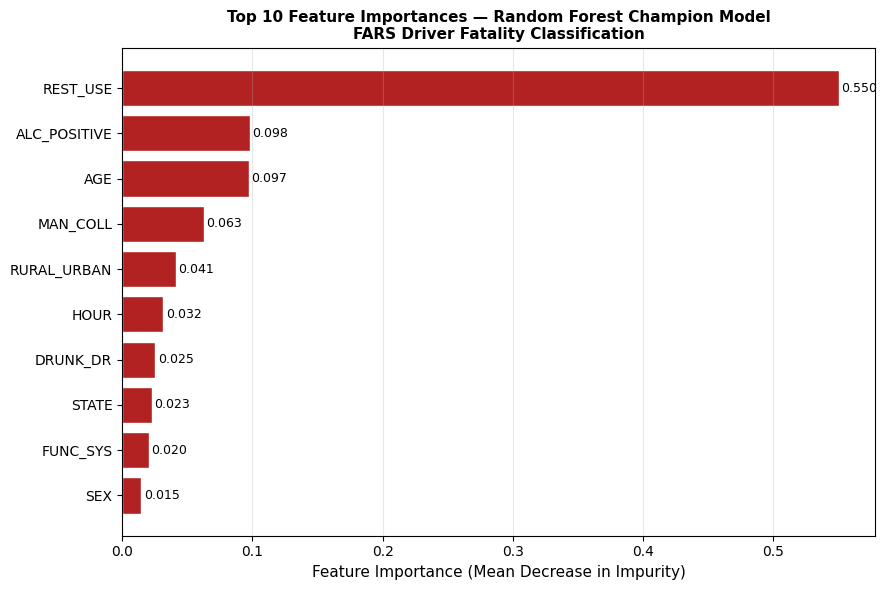

Figure saved.


In [11]:
importances = pd.Series(rf_model.feature_importances_, index=FEATURES)
importances = importances.sort_values(ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(importances.index, importances.values, color='firebrick', edgecolor='white')

ax.set_xlabel('Feature Importance (Mean Decrease in Impurity)', fontsize=11)
ax.set_title('Top 10 Feature Importances — Random Forest Champion Model\nFARS Driver Fatality Classification',
             fontsize=11, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

for bar in bars:
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/figures/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')

## 10. Summary

Results on the 2016 validation set (corrected run, November 2026):

| Metric | Logistic Regression | Random Forest | Difference |
|--------|--------------------|--------------|-----------|
| Accuracy | 76.72% | **77.20%** | +0.48 pp |
| Precision | **78.06%** | 77.05% | −1.01 pp |
| Recall | 69.18% | **72.30%** | +3.12 pp |
| F1 Score | 0.7335 | **0.7460** | +0.0125 |
| AUC-ROC | 0.8292 | **0.8434** | +0.0142 |

Random Forest is the **champion**: it leads on accuracy, recall, F1 and AUC, while Logistic Regression is slightly more precise. The recall gain is the most practically useful difference, because it means fewer fatal outcomes missed.

Compared with the original May 2026 run (Random Forest AUC 0.875, LR 0.834), scores are somewhat lower and the gap between models is smaller. That is expected: the original run included `FATALS`, which partly revealed the outcome, and mis-coded alcohol and rural/urban features.

SHAP interpretability analysis is conducted in `05_shap_analysis.ipynb`.